# Card 03 – Customers
**Question:** who comes back – and can we trust the customer data enough to build loyalty on it?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

In [2]:
so, cu = full_years(files['orders']), files['customers']
print(f'orders without a customer_id: {so.customer_id.isna().mean():.1%}')
(so.groupby('channel').customer_id.apply(lambda s: s.isna().mean() * 100).round(1)).to_frame('% orders without customer')

orders without a customer_id: 19.1%


,% orders without customer
channel,
Online,18.9
Store,19.1
Wholesale,19.3


19% of orders have no customer – **also online**, where a customer must log in or give a phone number to receive the parcel. That is a data capture gap.

In [3]:
x = so.merge(cu[['customer_id', 'customer_segment']], on='customer_id', how='left')
ct = pd.crosstab(x.channel, x.customer_segment)
ct['% B2B'] = ct['B2B reseller'] / ct.sum(axis=1) * 100
ct.round(1)

customer_segment,B2B reseller,Retail,% B2B
channel,,,
Online,1488,77073,1.9
Store,6165,305232,2.0
Wholesale,843,42479,1.9


The **wholesale channel** (38% of sales, ~24 pieces per order) is bought almost only by customers registered as *Retail*.
So the B2B segment flag does not describe who the resellers are.

customers with 5+ store visits: 27,441 | avg visits 7.7 | in 7.3 branches | 5.6 governorates


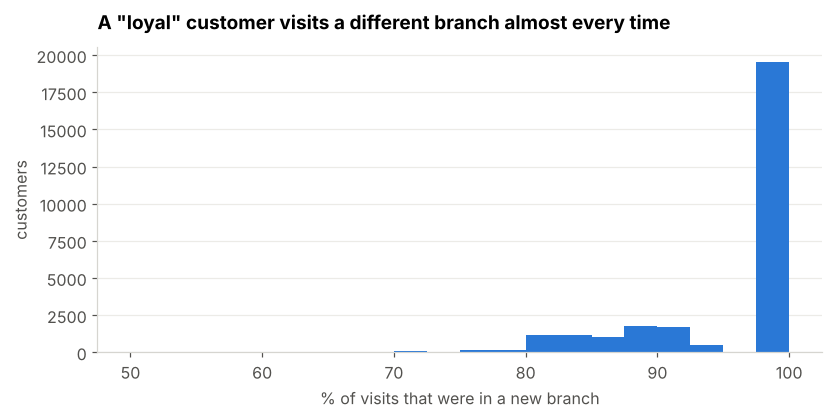

In [4]:
st = so[(so.channel == 'Store') & so.customer_id.notna()].merge(files['branches'][['branch_id', 'governorate_ar']], on='branch_id')
v = st.groupby('customer_id').agg(visits=('sales_order_id', 'size'), branches=('branch_id', 'nunique'), govs=('governorate_ar', 'nunique'))
v5 = v[v.visits >= 5]
print(f'customers with 5+ store visits: {len(v5):,} | avg visits {v5.visits.mean():.1f} | in {v5.branches.mean():.1f} branches | {v5.govs.mean():.1f} governorates')
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hist(v5.branches / v5.visits * 100, bins=20, color=BLUE)
style(ax, 'A "loyal" customer visits a different branch almost every time', 'customers')
ax.set_xlabel('% of visits that were in a new branch')
save(fig, 'c03_identity_branches')

In [5]:
r = so.merge(cu[['customer_id', 'customer_segment']], on='customer_id')
r = r[r.customer_segment == 'Retail']
snap = pd.Timestamp('2026-10-01')
p = r.groupby('customer_id').agg(last=('order_date', 'max'), orders=('sales_order_id', 'size'), spend=('net_before_tax_EGP', 'sum'))
p['recency_days'] = (snap - p['last']).dt.days
p['R'] = pd.qcut(p.recency_days, 5, labels=[5, 4, 3, 2, 1]).astype(int)
p['F'] = pd.qcut(p.orders.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
p['M'] = pd.qcut(p.spend, 5, labels=[1, 2, 3, 4, 5]).astype(int)
p['segment'] = np.select(
    [(p.R >= 4) & (p.F >= 4), (p.R >= 3) & (p.F >= 3), (p.R >= 4) & (p.F <= 2), (p.R <= 2) & (p.F >= 4), (p.R <= 2) & (p.F == 3), (p.R == 3)],
    ['Champions', 'Loyal', 'New / Promising', "At Risk (Can't Lose)", 'At Risk', 'Need Attention'], default='Lost')
seg = p.groupby('segment').agg(customers=('orders', 'size'), revenue=('spend', 'sum'), avg_orders=('orders', 'mean'))
seg['% customers'] = seg.customers / seg.customers.sum() * 100
seg['% revenue'] = seg.revenue / seg.revenue.sum() * 100
seg = seg.sort_values('revenue', ascending=False)
print(f'retail customers who bought: {len(p):,} | bought more than once: {(p.orders > 1).mean():.1%} | avg orders {p.orders.mean():.1f}')
s = p.spend.sort_values(ascending=False)
print(f'top 20% of customers = {s.head(len(s) // 5).sum() / s.sum():.1%} of retail revenue')
seg.round(1)

retail customers who bought: 72,731 | bought more than once: 86.8% | avg orders 5.8
top 20% of customers = 50.3% of retail revenue


,customers,revenue,avg_orders,% customers,% revenue
segment,,,,,
Champions,12617,190213469.8,10.1,17.3,29.0
Loyal,14694,169676651.3,6.9,20.2,25.9
At Risk (Can't Lose),10523,117066516.6,10.1,14.5,17.9
New / Promising,10734,58124990.1,2.1,14.8,8.9
Lost,12714,49190180.2,2.1,17.5,7.5
At Risk,5804,42646976.5,4.9,8.0,6.5
Need Attention,5645,28792309.0,2.1,7.8,4.4


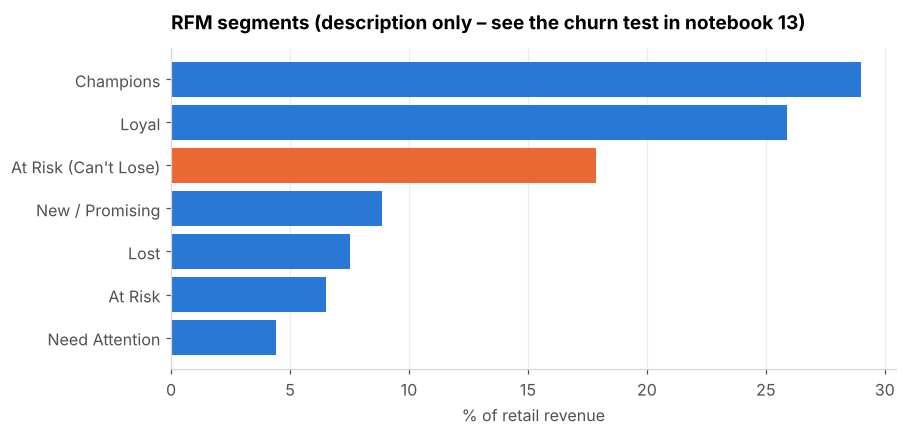

fy,2019,2020,2021,2022,2023,2024,2025,2026
active retail customers,7573,14975,21311,26876,32657,38544,44564,50225


In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sg = seg.sort_values('% revenue')
ax.barh(sg.index, sg['% revenue'], color=[ORANGE if i == "At Risk (Can't Lose)" else BLUE for i in sg.index])
style(ax, 'RFM segments (description only – see the churn test in notebook 13)')
ax.grid(axis='x', color='#ecebe7'); ax.grid(axis='y', visible=False); ax.set_xlabel('% of retail revenue')
save(fig, 'c03_rfm_segments')
act = full_years(r).groupby('fy').customer_id.nunique()
act.to_frame('active retail customers').T

### Takeaway (card 03)
- Active customers grow every year (7.6K → 50.2K), 86.8% buy more than once, the top 20% bring ~50% of revenue.
- **But the customer identity is weak**: 19% of orders (even online) have no customer, a "loyal" customer shops in ~7 branches and ~5.6 governorates, and resellers are registered as retail.
- RFM is shown as a **description** only. Whether we can *predict* who will leave is tested honestly in notebook 13.
- Fix first: one loyalty ID at the till (phone number) + a reseller flag – then personalise.